# Google Quick, Draw! — CNN Tuning
**Tuning order and reasons**
| Step | Hyperparameter | Values | Why |
|---|---|---|---|
| 1 | Dropout | 0.3, 0.4, 0.5 | v1 overfits mildly after epoch 5 |
| 2 | Learning rate | 1e-3, 5e-4 | a smaller step may reach a lower validation loss |
| 3 | Conv filters | 32/64, 64/128 | does more capacity help or just overfit? |
| 4 | Batch size | 64, 128 | gradient noise vs speed |
| 5 | Third conv block | off, on | deeper features for complex classes |

**Selection rule:** keep a new value only if it improves validation macro F1 by at least 0.005 (≈12 of 2,400 images). Otherwise keep the simpler or current value, since smaller gains may be noise.


## 1. Setup and data

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
data_path = Path("../data/quickdraw/quickdraw_8class_processed.npz")
figures_dir = Path("../figures")
results_dir = Path("../results")
figures_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

data = np.load(data_path)
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
# Test set deliberately NOT loaded: tuning must never see it
categories = data["categories"].tolist()
n_classes = len(categories)

print("TensorFlow:", tf.__version__)
print("Train:", X_train.shape, "Val:", X_val.shape)

TensorFlow: 2.21.0
Train: (19200, 28, 28, 1) Val: (2400, 28, 28, 1)


## 2. Model builder and experiment runner

In [2]:
def build_cnn(filters=(32, 64), third_block=False, dense_units=128, dropout=0.3, learning_rate=1e-3, **_):
    """Same architecture as CNN v1, with the tunable parts exposed as arguments."""
    model_layers = [
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(filters[0], (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),                                  # 28 -> 14
        layers.Conv2D(filters[1], (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),                                  # 14 -> 7
    ]
    if third_block:
        model_layers += [
            layers.Conv2D(filters[1] * 2, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),                              # 7 -> 3
        ]
    model_layers += [
        layers.Flatten(),
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(n_classes, activation="softmax"),
    ]
    model = keras.Sequential(model_layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


runs = {}   # cache: config -> result, so an identical config is never trained twice

def config_key(cfg):
    return json.dumps(cfg, sort_keys=True)

def run_experiment(cfg, max_epochs=30, patience=3):
    """Train one configuration with early stopping and score it on VALIDATION only."""
    key = config_key(cfg)
    if key in runs:
        return runs[key]

    keras.utils.set_random_seed(SEED)             # same seed for every run => fair comparison
    model = build_cnn(**cfg)
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)

    start = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=max_epochs, batch_size=cfg["batch_size"],
                        callbacks=[early_stop], verbose=0)
    train_time = time.perf_counter() - start

    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_val, val_pred, average="macro")
    h = history.history
    best_epoch = int(np.argmin(h["val_loss"])) + 1

    result = {
        "config": dict(cfg),
        "row": {
            "run": len(runs) + 1,
            "filters": "/".join(map(str, cfg["filters"])),
            "third_block": cfg["third_block"],
            "dropout": cfg["dropout"],
            "learning_rate": cfg["learning_rate"],
            "batch_size": cfg["batch_size"],
            "params": model.count_params(),
            "epochs_run": len(h["loss"]),
            "best_epoch": best_epoch,
            "best_val_loss": round(float(min(h["val_loss"])), 4),
            "train_acc_at_best": round(float(h["accuracy"][best_epoch - 1]), 4),
            "val_accuracy": round(float(accuracy_score(y_val, val_pred)), 4),
            "val_macro_precision": round(float(p), 4),
            "val_macro_recall": round(float(r), 4),
            "val_macro_f1": round(float(f1), 4),
            "train_time_s": round(train_time, 1),
        },
        "history": h,
        "model": model,
        "val_pred": val_pred,
    }
    runs[key] = result
    print(f"run {result['row']['run']:2d} | {cfg} -> val acc {result['row']['val_accuracy']:.4f}, "
          f"macro F1 {result['row']['val_macro_f1']:.4f}, {train_time:.0f}s")
    return result

## 3. One-at-a-time tuning
Each step tries the listed values with everything else fixed at the current best, then keeps the winner (selection rule above).
**Expect this cell to take a while** (about 10 runs, minutes each on a CPU).

In [3]:
MIN_GAIN = 0.005   # minimum macro-F1 improvement needed to switch to a new value

# Starting point = CNN v1
current = {"filters": (32, 64), "third_block": False, "dense_units": 128,
           "dropout": 0.3, "learning_rate": 1e-3, "batch_size": 64}

search_steps = [
    ("dropout",       [0.3, 0.4, 0.5]),
    ("learning_rate", [1e-3, 5e-4]),
    ("filters",       [(32, 64), (64, 128)]),
    ("batch_size",    [64, 128]),
    ("third_block",   [False, True]),
]

decisions = []
for param, values in search_steps:
    print(f"\n=== Tuning {param}: {values} ===")
    baseline = run_experiment(current)                     # current best (cached after first run)
    best_value, best_f1 = current[param], baseline["row"]["val_macro_f1"]

    for v in values:
        if v == current[param]:
            continue
        res = run_experiment({**current, param: v})
        if res["row"]["val_macro_f1"] >= best_f1 + MIN_GAIN:
            best_value, best_f1 = v, res["row"]["val_macro_f1"]

    decisions.append({"step": param, "tried": str(values), "kept": str(best_value), "val_macro_f1": best_f1})
    current[param] = best_value
    print(f"--> keep {param} = {best_value}")

best = run_experiment(current)
print("\nBest configuration:", best["config"])


=== Tuning dropout: [0.3, 0.4, 0.5] ===
run  1 | {'filters': (32, 64), 'third_block': False, 'dense_units': 128, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 64} -> val acc 0.9479, macro F1 0.9479, 25s
run  2 | {'filters': (32, 64), 'third_block': False, 'dense_units': 128, 'dropout': 0.4, 'learning_rate': 0.001, 'batch_size': 64} -> val acc 0.9513, macro F1 0.9514, 36s
run  3 | {'filters': (32, 64), 'third_block': False, 'dense_units': 128, 'dropout': 0.5, 'learning_rate': 0.001, 'batch_size': 64} -> val acc 0.9504, macro F1 0.9505, 35s
--> keep dropout = 0.3

=== Tuning learning_rate: [0.001, 0.0005] ===
run  4 | {'filters': (32, 64), 'third_block': False, 'dense_units': 128, 'dropout': 0.3, 'learning_rate': 0.0005, 'batch_size': 64} -> val acc 0.9500, macro F1 0.9500, 33s
--> keep learning_rate = 0.001

=== Tuning filters: [(32, 64), (64, 128)] ===
run  5 | {'filters': (64, 128), 'third_block': False, 'dense_units': 128, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size'

## 4. Results table (all runs, validation set)

In [4]:
results_df = pd.DataFrame([r["row"] for r in runs.values()]).sort_values("run")
results_df.to_csv(results_dir / "quickdraw_cnn_tuning.csv", index=False)
display(results_df)

print("\nDecision at each step:")
display(pd.DataFrame(decisions))

,run,filters,third_block,dropout,learning_rate,batch_size,params,epochs_run,best_epoch,best_val_loss,train_acc_at_best,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,train_time_s
0,1,32/64,False,0.3,0.0010,64,421384,8,5,0.1743,0.9539,0.9479,0.9480,0.9479,0.9479,24.8
1,2,32/64,False,0.4,0.0010,64,421384,12,9,0.1724,0.9681,0.9513,0.9517,0.9512,0.9514,35.8
2,3,32/64,False,0.5,0.0010,64,421384,12,9,0.1704,0.9614,0.9504,0.9510,0.9504,0.9505,35.2
3,4,32/64,False,0.3,0.0005,64,421384,12,9,0.1722,0.9632,0.9500,0.9500,0.9500,0.9500,32.6
4,5,64/128,False,0.3,0.0010,64,878472,9,6,0.1805,0.9708,0.9487,0.9489,0.9487,0.9487,60.4
5,6,32/64,False,0.3,0.0010,128,421384,9,6,0.1799,0.9535,0.9487,0.9490,0.9487,0.9488,27.7
6,7,32/64,True,0.3,0.0010,64,241288,8,5,0.1566,0.9626,0.9554,0.9560,0.9554,0.9556,28.1



Decision at each step:


,step,tried,kept,val_macro_f1
0,dropout,"[0.3, 0.4, 0.5]",0.3,0.9479
1,learning_rate,"[0.001, 0.0005]",0.001,0.9479
2,filters,"[(32, 64), (64, 128)]","(32, 64)",0.9479
3,batch_size,"[64, 128]",64,0.9479
4,third_block,"[False, True]",True,0.9556


After reviewing the results we noticed that most of the hyperparameters had little influence. Our first model (run 1) achieved a validation macro F1 score of 0.9479. When changing the dropout to 0.4 or 0.5 the scores were 0.9514 and 0.9505 respectively (learning rate of 0.0005 results in a score of 0.9500, batch size of 128 results in a score of 0.9488). All these numbers are about 0.4 percentage points apart, which is only 8 more correctly identified images out of 2,400 in the validation dataset. Such small variations can be explained by randomness as we run the only one iteration for each with one seed. Thus, we decide to stick with the original parameters (dropout 0.3, learning rate 0.001 and batch size 64).

Adding a third convolutional block (run 7) was the only change with a visible effect. This increased the validation macro F1 to 0.9556 and resulted in the lowest validation loss across all iterations (0.1566 vs. 0.17–0.18). The training and validation accuracies were very close (0.9626 and 0.9554 respectively), suggesting there was little overfitting. A surprise for us was that this model has fewer parameters than the original model (241,288 vs. 421,384). The feature map dimensions are reduced (from 7x7 to 3x3) before they reach the dense layer, which has the most parameters. This is done by adding a pooling layer. It got better because it was deeper, not bigger.

But the network just grew and grew and it didn’t work. Increasing the filters to 64/128 (run 5) almost doubled the number of parameters to 878,472 and training accuracy to 0.9708, which is the highest of all the runs. The validation macro F1 changed very little (0.9487), the validation loss was the highest among all iterations (0.1805), and the training time was about 2.5 times longer (67.9s vs. 27.6s). This indicates the beginning of overfitting, where the model is performing well on the training data but not on the validation data. Generally, adding more filters only helps the model to memorise the training data better, while adding an extra layer helps to learn more useful patterns and improves the performance on unseen illustrations.

## 5. Best model: curves, confusion matrix, misclassifications (validation)

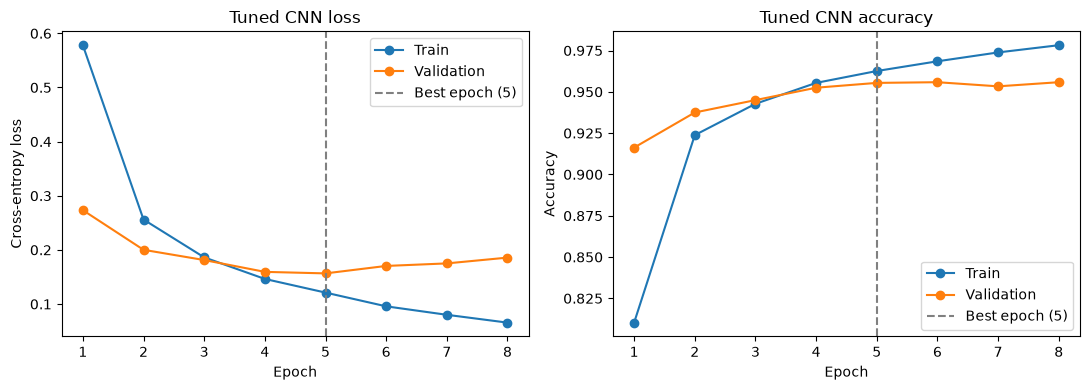

In [5]:
h = best["history"]
ep = range(1, len(h["loss"]) + 1)
b_ep = best["row"]["best_epoch"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, label in [(axes[0], "loss", "Cross-entropy loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(ep, h[metric], marker="o", label="Train")
    ax.plot(ep, h[f"val_{metric}"], marker="o", label="Validation")
    ax.axvline(b_ep, color="grey", linestyle="--", label=f"Best epoch ({b_ep})")
    ax.set_title(f"Tuned CNN {metric}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend()
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_best_curves.png", dpi=150, bbox_inches="tight")
plt.show()

              precision    recall  f1-score   support

    airplane     0.9347    0.9067    0.9205       300
       apple     0.9669    0.9733    0.9701       300
     bicycle     0.9829    0.9600    0.9713       300
         cat     0.8861    0.9333    0.9091       300
        fish     0.9311    0.9467    0.9388       300
      guitar     0.9702    0.9767    0.9734       300
       house     0.9932    0.9800    0.9866       300
        tree     0.9831    0.9667    0.9748       300

    accuracy                         0.9554      2400
   macro avg     0.9560    0.9554    0.9556      2400
weighted avg     0.9560    0.9554    0.9556      2400



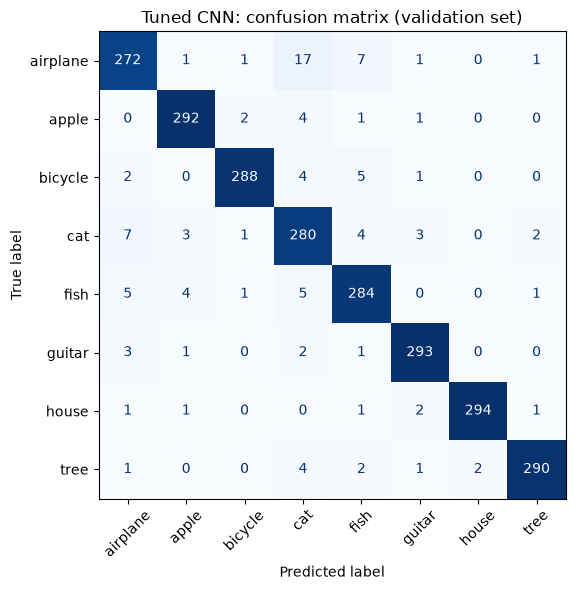

Most common confusions (true -> predicted : count):
  airplane  -> cat       : 17
  cat       -> airplane  : 7
  airplane  -> fish      : 7
  fish      -> airplane  : 5
  bicycle   -> fish      : 5


In [6]:
val_pred = best["val_pred"]
print(classification_report(y_val, val_pred, target_names=categories, digits=4))

cm = confusion_matrix(y_val, val_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=categories).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Tuned CNN: confusion matrix (validation set)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_best_confusion_val.png", dpi=150, bbox_inches="tight")
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
order = np.argsort(off.ravel())[::-1][:5]
print("Most common confusions (true -> predicted : count):")
for t, p in zip(*np.unravel_index(order, cm.shape)):
    print(f"  {categories[t]:9s} -> {categories[p]:9s} : {off[t, p]}")

## 6. Save the best model for the final test evaluation

In [7]:
best["model"].save(results_dir / "quickdraw_cnn_best.keras")

best_cfg = {**best["config"], "filters": list(best["config"]["filters"])}
with open(results_dir / "quickdraw_cnn_best_config.json", "w") as f:
    json.dump({"config": best_cfg, "validation": best["row"]}, f, indent=2)

print("Saved model  ->", results_dir / "quickdraw_cnn_best.keras")
print("Saved config ->", results_dir / "quickdraw_cnn_best_config.json")

Saved model  -> ..\results\quickdraw_cnn_best.keras
Saved config -> ..\results\quickdraw_cnn_best_config.json


## 7. Comparison with the classical and MLP models (validation set)

| Model | Settings | Val accuracy | Val macro precision | Val macro recall | Val macro F1 |
|---|---|---|---|---|---|
| Majority baseline | always predicts one class | 0.1250 | 0.0156 | 0.1250 | 0.0278 |
| Decision Tree (tuned) | entropy, max_depth=12, min_samples_leaf=5 | 0.7342 | 0.7368 | 0.7342 | 0.7349 |
| Logistic Regression | C=0.1, lbfgs | 0.8392 | 0.8394 | 0.8392 | 0.8392 |
| Random Forest | 100 trees, min_samples_leaf=2 | 0.8908 | 0.8909 | 0.8908 | 0.8907 |
| kNN | k=5, Euclidean | 0.8954 | 0.8996 | 0.8954 | 0.8930 |
| MLP | 256-128, relu, alpha=0.01, lr=0.001 | 0.9033 | 0.905 | 0.903 | 0.9035 |
| CNN (ours, run 7) | 32/64 + third block, dropout 0.3 | 0.9554 | 0.9560 | 0.9554 | 0.9556 |

Each of the models was trained on the same 19,200 images and evaluated on the same 2,400 validation images using the same metrics. We checked that the SHA-256 hash of the dataset file is the same for the two notebooks, to enable a fair comparison. The highest scores were obtained by CNN with a macro F1 score of 0.9556. The best classical or MLP model was the MLP with score 0.9035, followed by kNN with 0.8930 and Random Forest with 0.8907. The CNN outperforms the MLP by around 5 percentage points, which means about 125 more validation drawings are classified correctly (2,293 vs. 2,168). All models perform significantly better than the baseline (12.5% accuracy), showing that they have all learned something useful from the pixels.

The main reason CNN performs better is because of the way it interprets images. All of the classical models, including the MLP, treat each drawing as a linear array of 784 pixel values. When you flatten an image, the model loses the spatial relationships between pixels and the drawing loses its two-dimensional form. These models also treat each pixel location as independent. If one person draws a fish slightly to the left and another draws it slightly to the right, the strokes will end up on completely different pixels, and the model will have to learn each rendition separately. This is a big problem for sketches . People draw objects in different positions, sizes and orientations.

CNNs are designed to process visual data. Its filters look at small parts of the image one at a time, so the first layers learn basic local patterns like edges, curves and corners, and the later layers combine these into larger shapes like wheels, roofs or wings. This is known as spatial inductive bias: the model is based on the assumption that neighbouring pixels are related, which is indeed the case for images. The CNN uses weight sharing which means that the same filter goes over the entire image. If it learns to recognise a curve in one place, it can recognise that curve anywhere in the drawing, so it does much better with drawings that have been moved around.

If you want to show that the architecture matters and not just the size of the model , the best way is to compare the CNN against the MLP . The best MLP (256-128) has around 235,000 parameters and ours CNN has 241,288 parameters, so they are almost equal in size. However, the CNN still has a 5 point advantage, indicating that the improvement is due to the use of convolutions rather than an increase in parameters. The MLP is able to learn non-linear combinations of pixels, this allows it to outperform traditional models but it is restricted to a 1D array so cannot use image structure as well as the CNN.

In [8]:
# Validation-set comparison of all Quick Draw models (same split, same metrics).
# Values copied from the output of the classical/MLP notebook (sections 11 and 12).
# CNN values are read from the results files, so they always match the saved model.
import json
tuning = pd.read_csv(results_dir / "quickdraw_cnn_tuning.csv")
with open(results_dir / "quickdraw_cnn_best_config.json") as f:
    best_val = json.load(f)["validation"]
v1 = tuning.loc[tuning["run"] == 1].iloc[0]

comparison = pd.DataFrame([
    {"model": "Logistic Regression (C=0.1)", "input": "784 flat", "val_accuracy": 0.8392, "val_macro_f1": 0.8392},
    {"model": "Decision Tree (tuned)",       "input": "784 flat", "val_accuracy": 0.7342, "val_macro_f1": 0.7349},
    {"model": "k-NN (k=5)",                  "input": "784 flat", "val_accuracy": 0.8954, "val_macro_f1": 0.8930},
    {"model": "Random Forest (100 trees)",   "input": "784 flat", "val_accuracy": 0.8908, "val_macro_f1": 0.8907},
    {"model": "MLP 5 (256-128, ReLU)",       "input": "784 flat", "val_accuracy": 0.9033, "val_macro_f1": 0.9035},
    {"model": "CNN v1",                      "input": "28x28x1",  "val_accuracy": v1["val_accuracy"], "val_macro_f1": v1["val_macro_f1"]},
    {"model": "CNN tuned (3 conv blocks)",   "input": "28x28x1",  "val_accuracy": best_val["val_accuracy"], "val_macro_f1": best_val["val_macro_f1"]},
])
comparison.to_csv(results_dir / "quickdraw_model_comparison_val.csv", index=False)
display(comparison)

,model,input,val_accuracy,val_macro_f1
0,Logistic Regression (C=0.1),784 flat,0.8392,0.8392
1,Decision Tree (tuned),784 flat,0.7342,0.7349
2,k-NN (k=5),784 flat,0.8954,0.8930
3,Random Forest (100 trees),784 flat,0.8908,0.8907
4,"MLP 5 (256-128, ReLU)",784 flat,0.9033,0.9035
5,CNN v1,28x28x1,0.9479,0.9479
6,CNN tuned (3 conv blocks),28x28x1,0.9554,0.9556


## 8. Findings
The best configuration was found in run 7. It has the same configuration as v1 (32/64 filters, dropout 0.3, Adam with learning rate 0.001, batch size 64) and adds a third convolutional block. Epoch 5 was chosen for early stopping. On validation set it achieved an accuracy of 0.9554, macro F1 of 0.9556, macro precision of 0.9560 and macro recall of 9554. This is an improvement of approximately 0.8 percentage points compared to our initial CNN (v1) which had a value of 0.9479 for both accuracy and macro F1. For standard images, the number of validation errors went down from 125 to 107. Despite the deeper depth, the tuned model has less parameters than v1 (241,288 vs 421,384) thanks to the reduction in feature maps brought by the additional pooling layer before the dense layer. It also had the lowest validation loss of all of our runs (0.1566). The only thing that obviously helped was the addition of the third block, because changing the dropout, learning rate, batch size or number of filters did not change much.

The validation confusion matrix shows the main issues that still exist. The airoplane class is the worst with only 272 out of 300 correct predictions. Most of its errors are being predicted as a cat (17) or a fish (7). The aircraft and cat are the most confused, with 24 errors each way (17 + 7). The airplane and fish are the next most confused, with 12 errors (7 + 5). Sometimes a fish is also predicted as a cat (5). The model most frequently mispredicts the cat class with 36 validation images from other classes misidentified as cats. The easiest classes are house (294/300), guitar (293/300) and apple (292/300), which have only few errors. Most of the other errors are related to the airplane, cat and fish that are often represented as a body with small pointy parts (e.g. wings, ears, fins or tails).